### Agglomerative hierarchical clustering

- Agglomerative Hierarchical Clustering is an unsupervised machine learning algorithm that groups similar data points together, starting with individual points and gradually merging them into larger clusters.

In [1]:
# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# Load the dataset
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
# Preprocess the text data
scaler = StandardScaler()
X=scaler.fit_transform(df)

print("Dataset standarized successfully.")

Dataset standarized successfully.


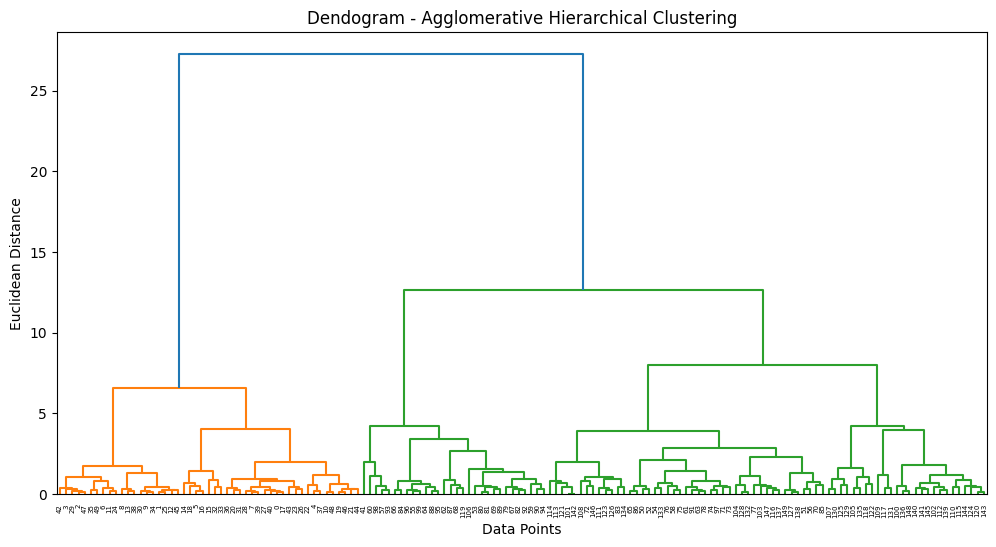

In [6]:
# Plot the dendrogram
linked = linkage(X, method='ward')
plt.figure(figsize=(12,6))
dendrogram(linked)
plt.title("Dendogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

In [7]:
# Apply Agglomerative Hierarchical Clustering
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['Cluster'] = model.fit_predict(X)
print(df.head())
print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  Cluster
0                5.1               3.5  ...               0.2        1
1                4.9               3.0  ...               0.2        1
2                4.7               3.2  ...               0.2        1
3                4.6               3.1  ...               0.2        1
4                5.0               3.6  ...               0.2        1

[5 rows x 5 columns]

Cluster Distribution:
Cluster
0    71
1    49
2    30
Name: count, dtype: int64


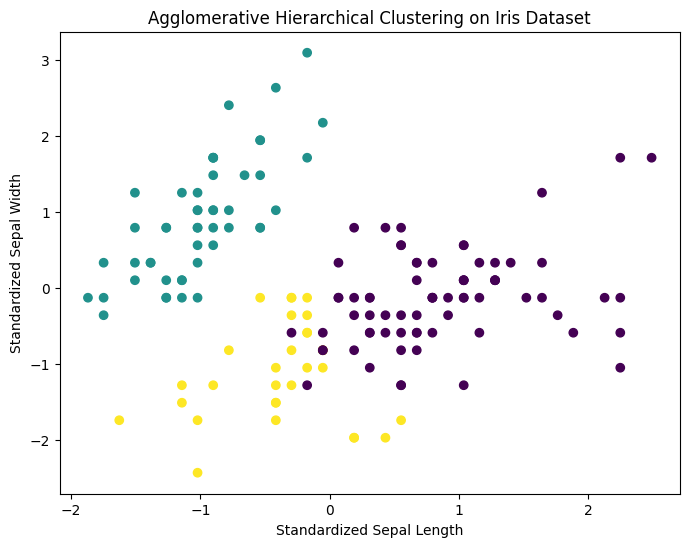

In [8]:
# Visualize the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=df["Cluster"],
    cmap="viridis"
)

plt.title("Agglomerative Hierarchical Clustering on Iris Dataset")
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.show()